# 01 — Análise exploratória do IPCA

**Pergunta do projeto:** dá para prever o IPCA dos próximos 1, 3 e 6 meses com erro menor do que um modelo ingênuo,
e as variáveis macroeconômicas (Selic e câmbio) ajudam nessa previsão?

Este notebook olha a série antes de qualquer modelo: tendência, sazonalidade, autocorrelação, estacionariedade e a
relação do IPCA com a Selic e o câmbio. Os dados vêm da cópia congelada em `data/raw/` (ver `src/coleta.py`); nada
aqui chama a API do Banco Central.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.coleta import ARQUIVO_METADADOS, carregar_series

FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Paleta categórica de referência (ordem fixa) e tinta de texto.
AZUL, LARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRADE, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.titlecolor": TEXTO, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png")

df = carregar_series()
print(json.dumps(json.loads(ARQUIVO_METADADOS.read_text(encoding="utf-8")), ensure_ascii=False, indent=1))
df.tail()

{
 "fonte": "Banco Central do Brasil — SGS",
 "series": {
  "ipca": 433,
  "selic": 4390,
  "cambio": 3698
 },
 "data_download": "2026-10-14T13:03:58-03:00",
 "periodo_inicio": "2003-01",
 "periodo_fim": "2026-09",
 "meses": 285,
 "python_bcb": "0.4.0"
}


,ipca,selic,cambio
data,,,
2026-05-01,0.58,1.07,4.9837
2026-06-01,0.16,1.12,5.1276
2026-07-01,0.07,1.22,5.1139
2026-08-01,-0.32,1.09,5.1532
2026-09-01,0.82,1.08,5.1447


## 1. Visão geral dos dados

In [2]:
print(df.info())
df.describe().round(2)

<class 'pandas.DataFrame'>
DatetimeIndex: 285 entries, 2003-01-01 to 2026-09-01
Freq: MS
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ipca    285 non-null    float64
 1   selic   285 non-null    float64
 2   cambio  285 non-null    float64
dtypes: float64(3)
memory usage: 8.9 KB
None


,ipca,selic,cambio
count,285.00,285.00,285.00
mean,0.47,0.91,3.35
std,0.35,0.35,1.38
min,-0.68,0.13,1.56
25%,0.25,0.71,2.15
50%,0.44,0.92,3.10
75%,0.64,1.11,4.91
max,2.25,2.08,6.10


O IPCA mensal oscila muito de um mês para o outro. Para enxergar o nível da inflação, uso também o **IPCA
acumulado em 12 meses** (o número que aparece no noticiário e na meta do Banco Central), calculado compondo as
variações mensais. Ele serve só para leitura: o alvo da previsão continua sendo o IPCA mensal.

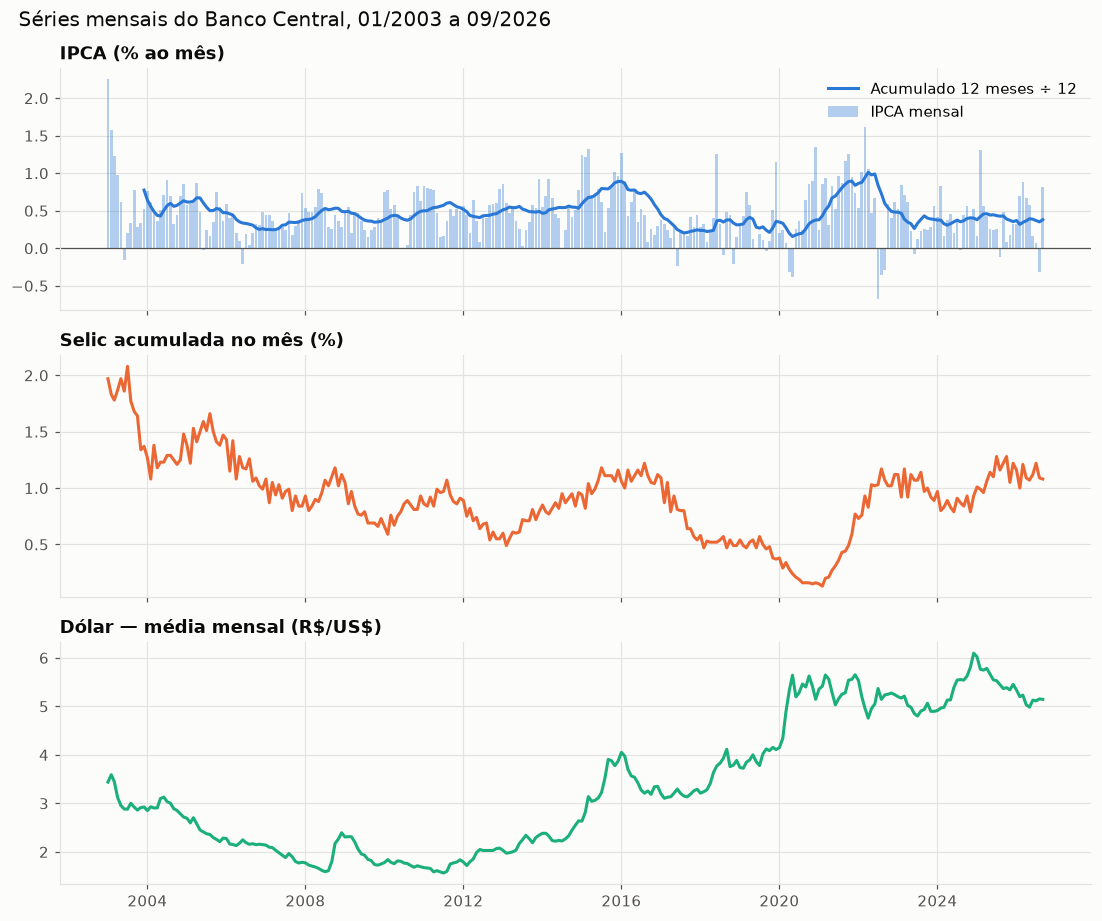

In [3]:
df["ipca_12m"] = ((1 + df["ipca"] / 100).rolling(12).apply(np.prod, raw=True) - 1) * 100

fig, eixos = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
eixos[0].bar(df.index, df["ipca"], width=25, color=AZUL, alpha=0.35, label="IPCA mensal")
eixos[0].plot(df.index, df["ipca_12m"] / 12, color=AZUL, label="Acumulado 12 meses ÷ 12")
eixos[0].set_title("IPCA (% ao mês)")
eixos[0].axhline(0, color=TEXTO_2, linewidth=0.8)
eixos[0].legend(frameon=False, loc="upper right")
eixos[1].plot(df.index, df["selic"], color=LARANJA)
eixos[1].set_title("Selic acumulada no mês (%)")
eixos[2].plot(df.index, df["cambio"], color=VERDE)
eixos[2].set_title(r"Dólar — média mensal (R\$/US\$)")
fig.suptitle(f"Séries mensais do Banco Central, {df.index.min():%m/%Y} a {df.index.max():%m/%Y}",
             x=0.01, ha="left", color=TEXTO, fontsize=13)
fig.tight_layout()
salvar(fig, "01_series")
plt.show()

In [4]:
ipca_12m = df["ipca_12m"].dropna()
print(f"IPCA 12 meses: mínimo {ipca_12m.min():.2f}% em {ipca_12m.idxmin():%m/%Y}, "
      f"máximo {ipca_12m.max():.2f}% em {ipca_12m.idxmax():%m/%Y}, último {ipca_12m.iloc[-1]:.2f}% em {ipca_12m.index[-1]:%m/%Y}")
print(f"Meses com IPCA negativo (deflação): {(df['ipca'] < 0).sum()} de {len(df)}")
print(f"IPCA mensal: média {df['ipca'].mean():.3f}, desvio-padrão {df['ipca'].std():.3f}")

IPCA 12 meses: mínimo 1.88% em 05/2020, máximo 12.13% em 04/2022, último 4.58% em 09/2026
Meses com IPCA negativo (deflação): 16 de 285
IPCA mensal: média 0.468, desvio-padrão 0.353


## 2. Tendência e sazonalidade

A decomposição **STL** separa o IPCA mensal em tendência, sazonalidade (período de 12 meses) e resíduo. Com
`robust=True`, os meses extremos (como os choques de 2015/2016 e 2021/2022) pesam menos na estimativa.

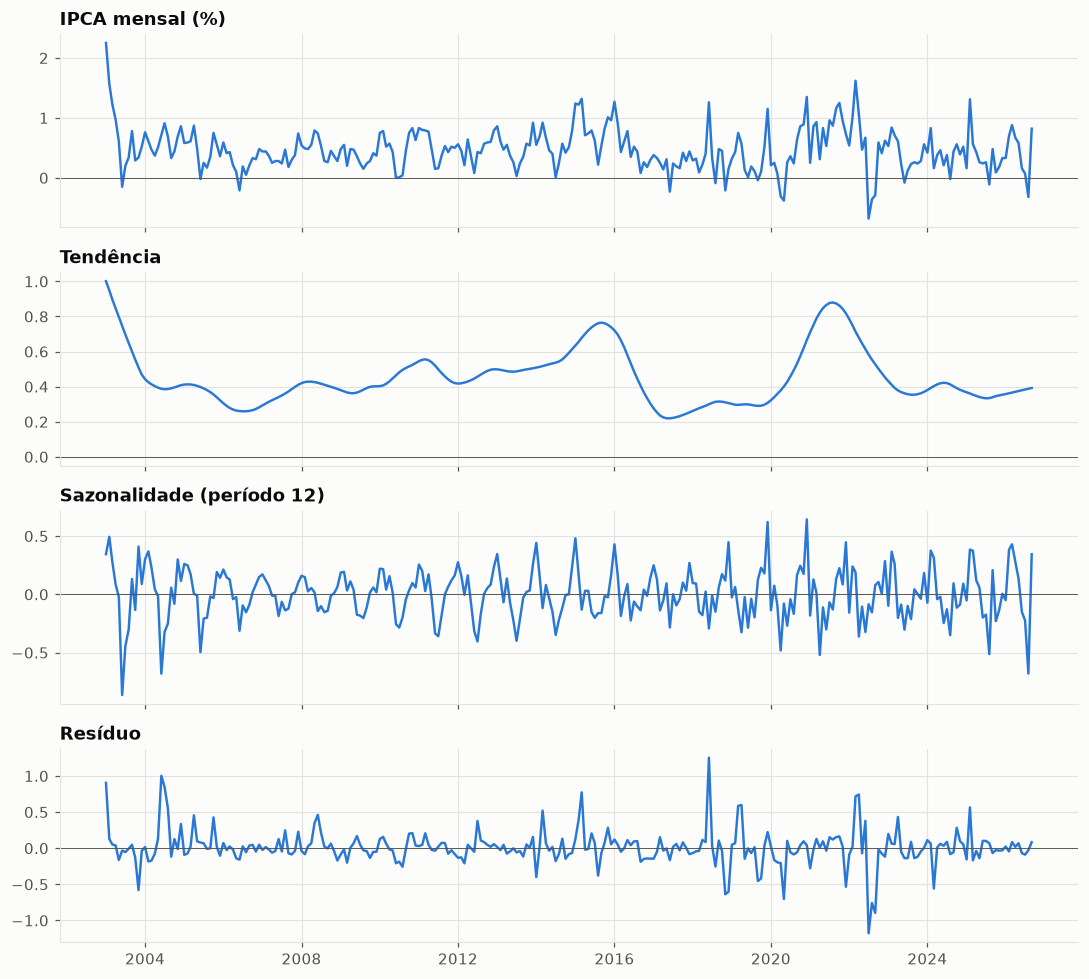

Força da tendência: 0.34 | força da sazonalidade: 0.34  (0 = nenhuma, 1 = total)


In [5]:
stl = STL(df["ipca"], period=12, robust=True).fit()

fig, eixos = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for eixo, serie, titulo in zip(
    eixos,
    [df["ipca"], stl.trend, stl.seasonal, stl.resid],
    ["IPCA mensal (%)", "Tendência", "Sazonalidade (período 12)", "Resíduo"],
):
    eixo.plot(serie.index, serie, color=AZUL, linewidth=1.6)
    eixo.set_title(titulo)
    eixo.axhline(0, color=TEXTO_2, linewidth=0.6)
fig.tight_layout()
salvar(fig, "02_stl_ipca")
plt.show()

var_resid = stl.resid.var()
forca_tendencia = max(0, 1 - var_resid / (stl.trend + stl.resid).var())
forca_sazonal = max(0, 1 - var_resid / (stl.seasonal + stl.resid).var())
print(f"Força da tendência: {forca_tendencia:.2f} | força da sazonalidade: {forca_sazonal:.2f}  (0 = nenhuma, 1 = total)")

A força de tendência e de sazonalidade (Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*,
seção 4.3) vai de 0 a 1 e resume quanto da variação cada componente explica em relação ao resíduo. Abaixo, o padrão
sazonal visto mês a mês: a distribuição do IPCA em cada mês do calendário.

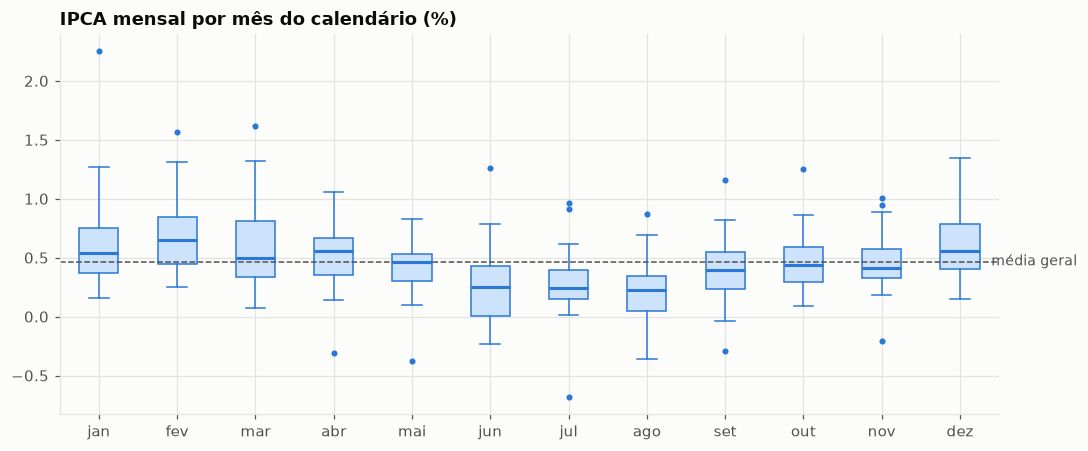

,jan,fev,mar,abr,mai,jun,jul,ago,set,out,nov,dez
mean,0.630,0.708,0.603,0.513,0.423,0.282,0.274,0.202,0.398,0.489,0.474,0.623
median,0.540,0.650,0.500,0.560,0.460,0.250,0.240,0.225,0.395,0.440,0.410,0.560
std,0.446,0.328,0.398,0.294,0.259,0.361,0.322,0.280,0.299,0.268,0.277,0.294


In [6]:
por_mes = df.groupby(df.index.month)["ipca"]
nomes = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

fig, eixo = plt.subplots(figsize=(10, 4.2))
eixo.boxplot([g.values for _, g in por_mes], tick_labels=nomes, widths=0.5, patch_artist=True,
             boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), medianprops=dict(color=AZUL, linewidth=2),
             whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
             flierprops=dict(marker="o", markersize=4, markerfacecolor=AZUL, markeredgecolor="none"))
eixo.axhline(df["ipca"].mean(), color=TEXTO_2, linewidth=1, linestyle="--")
eixo.annotate("média geral", xy=(12.4, df["ipca"].mean()), color=TEXTO_2, va="center", fontsize=9, annotation_clip=False)
eixo.set_title("IPCA mensal por mês do calendário (%)")
fig.tight_layout()
salvar(fig, "03_sazonalidade_mes")
plt.show()

por_mes.agg(["mean", "median", "std"]).set_axis(nomes).round(3).T

## 3. Autocorrelação

A **ACF** mostra a correlação do IPCA com ele mesmo k meses antes; a **PACF** mostra a correlação que sobra em cada
defasagem depois de descontar as intermediárias. A faixa sombreada é o intervalo de 95% sob a hipótese de ruído.

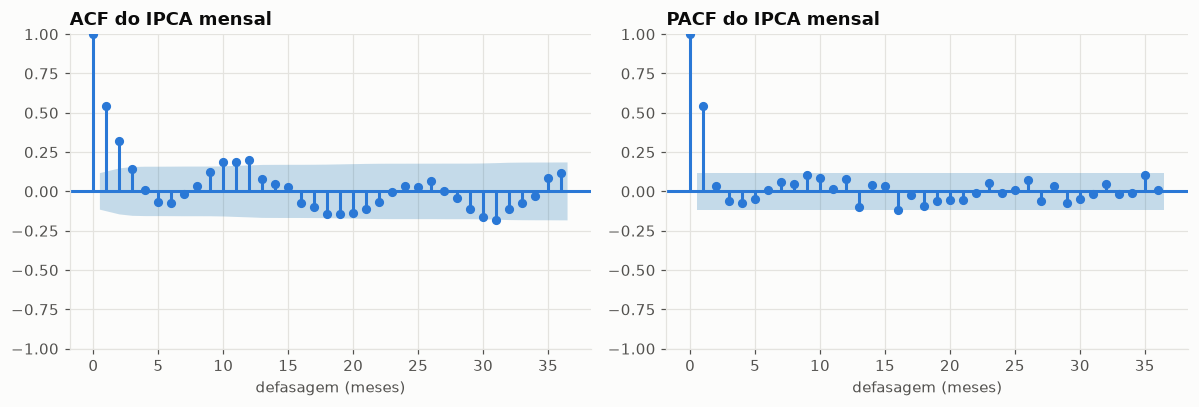

1     0.541
2     0.319
3     0.144
6    -0.071
12    0.199
24    0.033
Name: ACF, dtype: float64

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
plot_acf(df["ipca"], lags=36, ax=eixos[0], color=AZUL, vlines_kwargs={"colors": AZUL})
plot_pacf(df["ipca"], lags=36, ax=eixos[1], method="ywm", color=AZUL, vlines_kwargs={"colors": AZUL})
eixos[0].set_title("ACF do IPCA mensal")
eixos[1].set_title("PACF do IPCA mensal")
for eixo in eixos:
    eixo.set_xlabel("defasagem (meses)")
fig.tight_layout()
salvar(fig, "04_acf_pacf_ipca")
plt.show()

from statsmodels.tsa.stattools import acf
autocorr = pd.Series(acf(df["ipca"], nlags=24), name="ACF").round(3)
autocorr.loc[[1, 2, 3, 6, 12, 24]]

## 4. Estacionariedade

Dois testes com hipóteses opostas, que se complementam:

- **ADF** — H0: a série tem raiz unitária (não é estacionária). p-valor baixo → rejeita → indício de estacionariedade.
- **KPSS** — H0: a série é estacionária. p-valor baixo → rejeita → indício de não estacionariedade.

O câmbio é testado em nível e em variação percentual mensal, que é a forma que faria sentido usar no modelo se o
nível não for estacionário.

In [8]:
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning

df["cambio_var"] = df["cambio"].pct_change() * 100

def testes(serie):
    serie = serie.dropna()
    adf_p = adfuller(serie, autolag="AIC", result_object=False)[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)  # p-valor do KPSS fica limitado entre 0,01 e 0,10
        kpss_p = kpss(serie, regression="c", nlags="auto", result_object=False)[1]
    if adf_p < 0.05 and kpss_p >= 0.05:
        leitura = "estacionária"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        leitura = "não estacionária"
    else:
        leitura = "inconclusivo"
    return {"ADF p-valor": round(adf_p, 4), "KPSS p-valor": round(kpss_p, 4), "leitura (5%)": leitura}

estacionariedade = pd.DataFrame({
    "IPCA mensal": testes(df["ipca"]),
    "Selic no mês": testes(df["selic"]),
    "Câmbio (nível)": testes(df["cambio"]),
    "Câmbio (variação % mensal)": testes(df["cambio_var"]),
    "Selic (diferença mensal)": testes(df["selic"].diff()),
}).T
estacionariedade

,ADF p-valor,KPSS p-valor,leitura (5%)
IPCA mensal,0.0,0.1,estacionária
Selic no mês,0.165,0.01,não estacionária
Câmbio (nível),0.8769,0.01,não estacionária
Câmbio (variação % mensal),0.0,0.0982,estacionária
Selic (diferença mensal),0.0,0.1,estacionária


## 5. Relação do IPCA com a Selic e o câmbio

A pergunta que importa para a previsão é se o valor **passado** da Selic e do câmbio diz algo sobre o IPCA **de
hoje**. Por isso a correlação abaixo é entre o IPCA no mês t e a variável no mês t−k (k = 0 a 12), usando as formas
estacionárias da seção 4. Correlação aqui é só um indício: quem decide se as variáveis ajudam é o teste de ablação
com backtest, na semana 3.

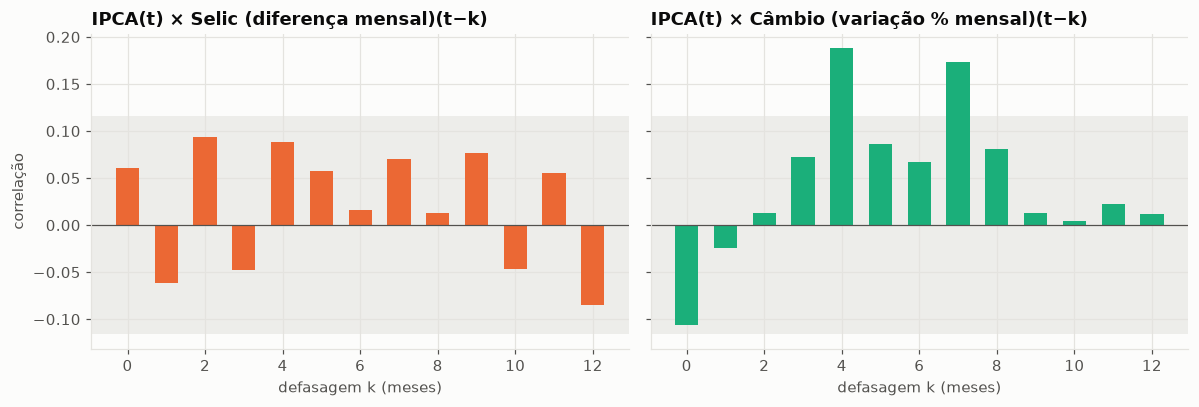

Faixa de 95% para correlação zero: ±0.116


,Selic (diferença mensal),Câmbio (variação % mensal)
0,0.061,-0.106
1,-0.061,-0.025
2,0.093,0.013
3,-0.048,0.072
4,0.088,0.188
5,0.057,0.086
6,0.016,0.067
7,0.070,0.174
8,0.013,0.081
9,0.076,0.013


In [9]:
def correlacao_defasada(alvo, x, defasagens=range(0, 13)):
    return pd.Series({k: alvo.corr(x.shift(k)) for k in defasagens})

corr = pd.DataFrame({
    "Selic (diferença mensal)": correlacao_defasada(df["ipca"], df["selic"].diff()),
    "Câmbio (variação % mensal)": correlacao_defasada(df["ipca"], df["cambio_var"]),
})
limite = 1.96 / np.sqrt(len(df))  # faixa de 95% para correlação zero

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for eixo, (nome, serie), cor in zip(eixos, corr.items(), [LARANJA, VERDE]):
    eixo.axhspan(-limite, limite, color=GRADE, alpha=0.6, linewidth=0, zorder=0)
    eixo.bar(serie.index, serie.values, color=cor, width=0.6, zorder=2)
    eixo.axhline(0, color=TEXTO_2, linewidth=0.8)
    eixo.set_title(f"IPCA(t) × {nome}(t−k)")
    eixo.set_xlabel("defasagem k (meses)")
    eixo.set_xticks(range(0, 13, 2))
eixos[0].set_ylabel("correlação")
fig.tight_layout()
salvar(fig, "05_correlacao_defasada")
plt.show()

print(f"Faixa de 95% para correlação zero: ±{limite:.3f}")
corr.round(3)

A correlação defasada não desconta a autocorrelação do próprio IPCA: se ele é persistente, parte da relação
aparente pode vir disso. O **teste de causalidade de Granger** pergunta exatamente o que a previsão precisa: as
defasagens da Selic/câmbio melhoram a previsão do IPCA **além** das defasagens do próprio IPCA?

In [10]:
from statsmodels.tsa.stattools import grangercausalitytests

def granger(alvo, x, defasagens=(1, 3, 6, 12)):
    dados = pd.concat([alvo, x], axis=1).dropna()
    resultado = grangercausalitytests(dados, maxlag=max(defasagens))
    return {f"{k} meses": round(resultado[k][0]["ssr_ftest"][1], 4) for k in defasagens}

import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):  # o statsmodels imprime cada teste
    granger_p = pd.DataFrame({
        "Selic (diferença mensal)": granger(df["ipca"], df["selic"].diff()),
        "Câmbio (variação % mensal)": granger(df["ipca"], df["cambio_var"]),
    }).T
print("p-valores do teste F (H0: a variável NÃO ajuda a prever o IPCA além do próprio passado)")
granger_p

p-valores do teste F (H0: a variável NÃO ajuda a prever o IPCA além do próprio passado)


,1 meses,3 meses,6 meses,12 meses
Selic (diferença mensal),0.0572,0.0662,0.0387,0.0656
Câmbio (variação % mensal),0.5088,0.6396,0.0572,0.0316


## 6. Estabilidade ao longo do tempo

Um backtest com janela expansiva treina com o passado e testa no futuro. Se o comportamento da série muda muito
entre períodos, os anos de teste podem ser bem diferentes dos de treino. Abaixo, média e volatilidade do IPCA
mensal em janelas móveis de 24 meses.

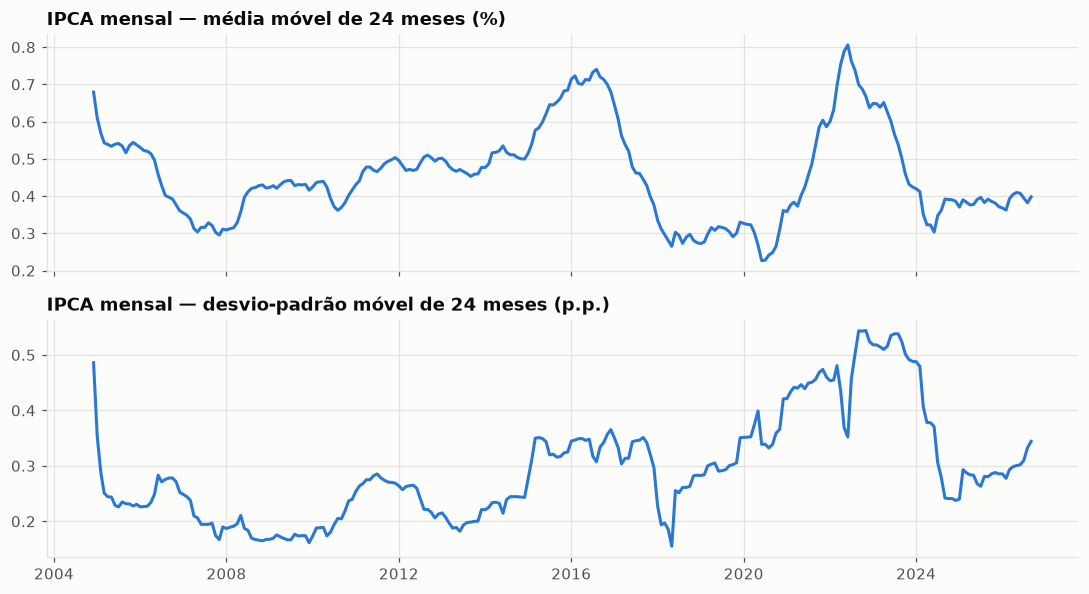

,mean,std,count
2003–08,0.487,0.354,72
2009–14,0.472,0.232,72
2015–19,0.452,0.377,60
2020–23,0.505,0.477,48
2024–26,0.388,0.315,33


In [11]:
janela = 24
fig, eixos = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
eixos[0].plot(df.index, df["ipca"].rolling(janela).mean(), color=AZUL)
eixos[0].set_title(f"IPCA mensal — média móvel de {janela} meses (%)")
eixos[1].plot(df.index, df["ipca"].rolling(janela).std(), color=AZUL)
eixos[1].set_title(f"IPCA mensal — desvio-padrão móvel de {janela} meses (p.p.)")
fig.tight_layout()
salvar(fig, "06_estabilidade")
plt.show()

por_periodo = df["ipca"].groupby(pd.cut(df.index.year, [2002, 2008, 2014, 2019, 2023, 2030],
                                        labels=["2003–08", "2009–14", "2015–19", "2020–23", "2024–26"]),
                                 observed=True).agg(["mean", "std", "count"]).round(3)
por_periodo

## 7. Referência para os modelos: o erro do modelo ingênuo

O baseline que os modelos precisam bater é o ingênuo: repetir o último IPCA observado. Uma primeira medida do seu
erro (sem backtest formal, que vem no notebook 02) dá a escala do problema: o MAE abaixo é o erro médio, em pontos
percentuais, de prever o IPCA de h meses à frente com o último valor conhecido.

In [12]:
ingenuo = pd.DataFrame({
    f"h = {h}": {
        "MAE (p.p.)": (df["ipca"] - df["ipca"].shift(h)).abs().mean(),
        "RMSE (p.p.)": np.sqrt(((df["ipca"] - df["ipca"].shift(h)) ** 2).mean()),
    }
    for h in (1, 3, 6)
}).round(3)
sazonal_ingenuo = (df["ipca"] - df["ipca"].shift(12)).abs().mean()
print(f"Para comparar: ingênuo sazonal (mesmo mês do ano anterior) tem MAE {sazonal_ingenuo:.3f} p.p.")
ingenuo

Para comparar: ingênuo sazonal (mesmo mês do ano anterior) tem MAE 0.312 p.p.


,h = 1,h = 3,h = 6
MAE (p.p.),0.238,0.334,0.367
RMSE (p.p.),0.320,0.440,0.497


## 8. Conclusões

**Nível e eventos.** No período, o IPCA acumulado em 12 meses foi de 1,88% (05/2020) a 12,13% (04/2022) e estava
em 4,58% em 09/2026. Houve 16 meses de deflação em 285. O início da série (jan–mar/2003) ainda carrega o choque
de 2002, com o maior valor mensal da amostra (2,25%) — vale tratar esses meses com cuidado nos modelos.

**Tendência e sazonalidade moderadas.** A força de ambas é 0,34 na STL. O padrão do calendário é claro: o IPCA é
mais alto em dezembro a março (média de 0,60 a 0,71% ao mês) e mais baixo em junho a agosto (0,20 a 0,28%). A ACF
confirma, com um pico de 0,20 na defasagem 12.

**Memória curta.** A ACF cai rápido (0,54 em 1 mês, 0,32 em 2, 0,14 em 3) e a PACF só é relevante na defasagem 1:
o comportamento lembra um AR(1) com componente sazonal. Isso aponta para um SARIMA com termos de ordem baixa e
sugere que, a partir de 3 meses à frente, o passado do próprio IPCA ajuda pouco.

**Estacionariedade.** O IPCA mensal é estacionário (ADF e KPSS concordam), então pode ser modelado sem
diferenciar. A Selic e o câmbio em nível não são; as formas estacionárias que entram nos modelos são a diferença
mensal da Selic e a variação percentual mensal do câmbio.

**Selic e câmbio: sinais fracos, mais no horizonte longo.**
- *Câmbio:* as correlações com o IPCA só saem da faixa de ruído nas defasagens de 4 meses (0,19) e 7 meses
  (0,17), coerente com o repasse cambial para os preços, que leva alguns meses. No teste de Granger ele não ajuda
  com 1 ou 3 defasagens (p = 0,51 e 0,64), fica no limite com 6 (p = 0,057) e é significativo com 12 (p = 0,032).
- *Selic:* nenhuma correlação defasada sai da faixa de ruído; no Granger os p-valores ficam entre 0,04 e 0,07.
- Leitura: para o horizonte de 1 mês não se espera ganho das variáveis macro; para 3 e 6 meses talvez. São muitos
  testes, então nada disso é conclusivo — quem responde a pergunta do projeto é a ablação com backtest (semana 3).

**Instabilidade.** A volatilidade do IPCA mensal mudou bastante: desvio-padrão de 0,23 p.p. em 2009–14 contra
0,48 p.p. em 2020–23. Um backtest com janela expansiva vai treinar em anos calmos e testar em anos agitados, então
os erros devem ser reportados também por período, e não só na média geral.

**O baseline a bater.** Repetir o último IPCA tem MAE de 0,24 p.p. em 1 mês, 0,33 em 3 e 0,37 em 6 (medido na
amostra inteira, sem backtest). O ingênuo **sazonal** (repetir o mesmo mês do ano anterior) tem MAE de 0,31 p.p.,
melhor que o ingênuo simples em 3 e 6 meses. Por isso o notebook 02 deve comparar os modelos com os dois baselines.
